### Cell 1 — Check Python and GPU

In [10]:
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

print("Python:", sys.version)
print("Project folder:", PROJECT)
print("Project exists:", PROJECT.exists())
print("PyTorch/GPU checks will follow in the next cell.")

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Project folder: c:\Projects\smoke_vehicle_detection
Project exists: True
PyTorch/GPU checks will follow in the next cell.


### Cell 2 — Inspect your dataset structure

In [11]:
from pathlib import Path

SMOKE_SOURCE = PROJECT / "-Smoke-Vehicles-Detection--2"
VEHICLE_SOURCE = PROJECT / "Dataset" / "vehicle detection"
ACCIDENT_SOURCE = PROJECT / "Dataset" / "accident feature"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def inspect_folder(folder):
    print(f"\n{'=' * 60}")
    print("Folder:", folder)
    print("Exists:", folder.exists())

    if not folder.exists():
        return

    # Show immediate contents
    print("\nContents:")
    for item in sorted(folder.iterdir()):
        print("  DIR " if item.is_dir() else "  FILE", item.name)

    # Count images recursively
    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]

    print("\nTotal images:", len(images))
    print("Examples:")
    for p in images[:5]:
        print(" ", p.relative_to(folder))

inspect_folder(SMOKE_SOURCE)
inspect_folder(VEHICLE_SOURCE)
inspect_folder(ACCIDENT_SOURCE)


Folder: c:\Projects\smoke_vehicle_detection\-Smoke-Vehicles-Detection--2
Exists: True

Contents:
  FILE data.yaml
  FILE README.dataset.txt
  FILE README.roboflow.txt
  DIR  test
  DIR  train
  DIR  valid

Total images: 2848
Examples:
  valid\images\000112_jpg.rf.a082a26ca5437311a01583b204379839.jpg
  valid\images\000120_jpg.rf.04df528d803a167431f1aa10af3a46dd.jpg
  valid\images\000120_jpg.rf.c8cdd385264f496dee6d4db446dd2c4f.jpg
  valid\images\000125_jpg.rf.ddce610fe9f33fe80f4211ce33bada47.jpg
  valid\images\000126_jpg.rf.7bddf3db4755a62d4d1ed1a83780df1d.jpg

Folder: c:\Projects\smoke_vehicle_detection\Dataset\vehicle detection
Exists: True

Contents:
  FILE .DS_Store
  DIR  test
  DIR  train
  DIR  valid

Total images: 1680
Examples:
  valid\images\101086563_283751446115758_7128739401279407536_n_jpg.rf.bd156698aa989b087b0884f4a5900650.jpg
  valid\images\117527068_2820312994739788_9201524732178672530_n_jpg.rf.6588486ebe225547d680bd271031a641.jpg
  valid\images\1242968975_jpg.rf.c8347b

### Cell 3 — Read the smoke dataset configuration

In [12]:
yaml_path = SMOKE_SOURCE / "data.yaml"

if yaml_path.exists():
    print(yaml_path.read_text(encoding="utf-8"))
else:
    print("data.yaml not found at:", yaml_path)

names:
- '0'
- black smoke
- blue smoke
- white smoke
nc: 4
roboflow:
  license: CC BY 4.0
  project: smoke-vehicles-detection
  url: https://universe.roboflow.com/student-project-wixsj/smoke-vehicles-detection/dataset/2
  version: 2
  workspace: student-project-wixsj
test: ../test/images
train: ../train/images
val: ../valid/images



### Cell 4 — Inspect the image labels

In [13]:
from collections import Counter

class_counts = Counter()
label_file_count = 0
empty_label_count = 0
missing_label_count = 0
invalid_label_examples = []

for split in ["train", "valid", "test"]:
    image_dir = SMOKE_SOURCE / split / "images"
    label_dir = SMOKE_SOURCE / split / "labels"

    print(f"\n{split}:")
    print("  images folder exists:", image_dir.exists())
    print("  labels folder exists:", label_dir.exists())

    if not image_dir.exists():
        continue

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            missing_label_count += 1
            continue

        label_file_count += 1
        lines = [
            line.strip()
            for line in label_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]

        if not lines:
            empty_label_count += 1

        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                invalid_label_examples.append((str(label_path), line))
                continue

            try:
                class_id = int(parts[0])
                coords = [float(x) for x in parts[1:]]
                class_counts[class_id] += 1
            except ValueError:
                invalid_label_examples.append((str(label_path), line))

print("\n========== LABEL AUDIT ==========")
print("Label files:", label_file_count)
print("Empty label files:", empty_label_count)
print("Images missing label files:", missing_label_count)
print("Bounding boxes by original class ID:", dict(class_counts))
print("Invalid label examples:", invalid_label_examples[:5])


train:
  images folder exists: True
  labels folder exists: True

valid:
  images folder exists: True
  labels folder exists: True

test:
  images folder exists: True
  labels folder exists: True

========== LABEL AUDIT ==========
Label files: 2848
Empty label files: 3
Images missing label files: 0
Bounding boxes by original class ID: {1: 1966, 2: 412, 3: 280, 0: 6}
Invalid label examples: [('c:\\Projects\\smoke_vehicle_detection\\-Smoke-Vehicles-Detection--2\\train\\labels\\000001_jpg.rf.0cd7928b5c990c423528ab8ff6287bbe.txt', '1 0.27494344921875 0.36919087109375 0.281777841796875 0.32056163671875 0.235084212890625 0.33203191015625 0.19328937109375 0.27656828125 0.17940554296875 0.279125193359375 0.17429171484375 0.2513575390625 0.1547444296875 0.26213482421875 0.071369787109375 0.245909125 0.039730919921875 0.2144136171875 0.001138115234375 0.45693848828125 0.02517791796875 0.478349697265625 0.085827056640625 0.495889693359375 0.1301071328125 0.53366996484375 0.347421259765625 0.5912

### Cell 5 — Check the original class names

In [14]:
import yaml

smoke_yaml = SMOKE_SOURCE / "data.yaml"

with open(smoke_yaml, "r", encoding="utf-8") as f:
    smoke_config = yaml.safe_load(f)

print("Class names:", smoke_config.get("names"))
print("Number of classes:", smoke_config.get("nc"))
print("\nFull configuration:")
print(smoke_config)

Class names: ['0', 'black smoke', 'blue smoke', 'white smoke']
Number of classes: 4

Full configuration:
{'names': ['0', 'black smoke', 'blue smoke', 'white smoke'], 'nc': 4, 'roboflow': {'license': 'CC BY 4.0', 'project': 'smoke-vehicles-detection', 'url': 'https://universe.roboflow.com/student-project-wixsj/smoke-vehicles-detection/dataset/2', 'version': 2, 'workspace': 'student-project-wixsj'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


### Cell 6 — Identify the annotation formats

In [15]:
from collections import Counter
from pathlib import Path

def audit_labels(dataset_root, dataset_name):
    print(f"\n========== {dataset_name} ==========")

    lengths = Counter()
    classes = Counter()
    examples = []

    for split in ["train", "valid", "test"]:
        label_dir = dataset_root / split / "labels"

        if not label_dir.exists():
            print(f"Missing labels folder: {label_dir}")
            continue

        for label_file in label_dir.glob("*.txt"):
            lines = [
                line.strip()
                for line in label_file.read_text(
                    encoding="utf-8"
                ).splitlines()
                if line.strip()
            ]

            for line in lines:
                parts = line.split()
                lengths[len(parts)] += 1

                try:
                    classes[parts[0]] += 1
                except IndexError:
                    pass

                if len(examples) < 8:
                    examples.append((label_file.name, line))

    print("Values per annotation line:", dict(lengths))
    print("Class IDs:", dict(classes))
    print("\nExamples:")

    for filename, line in examples:
        print(f"\n{filename}\n{line[:250]}")

audit_labels(SMOKE_SOURCE, "SMOKE DATASET")

audit_labels(
    PROJECT / "Dataset" / "vehicle detection",
    "VEHICLE DETECTION DATASET"
)


========== SMOKE DATASET ==========
Values per annotation line: {39: 19, 31: 39, 41: 10, 5: 2664, 17: 30, 35: 34, 19: 40, 33: 31, 27: 36, 23: 29, 29: 26, 77: 1, 81: 1, 79: 1, 25: 29, 11: 3, 13: 23, 15: 31, 49: 12, 45: 14, 51: 4, 21: 20, 57: 5, 53: 7, 37: 14, 73: 1, 43: 9, 85: 1, 75: 1, 55: 8, 47: 2, 59: 2, 63: 3, 61: 2, 111: 3, 9: 1}
Class IDs: {'1': 2296, '2': 484, '3': 370, '0': 6}

Examples:

000001_jpg.rf.0cd7928b5c990c423528ab8ff6287bbe.txt
1 0.27494344921875 0.36919087109375 0.281777841796875 0.32056163671875 0.235084212890625 0.33203191015625 0.19328937109375 0.27656828125 0.17940554296875 0.279125193359375 0.17429171484375 0.2513575390625 0.1547444296875 0.26213482421875 0.0713697871

000001_jpg.rf.3d77379e24f7dade1d1379653f523a8e.txt
1 0.506503337890625 0.489176626953125 0.396074673828125 0.47070005078125 0.352816119140625 0.389466544921875 0.3398210859375 0.3927065703125 0.33872943359375 0.406781611328125 0.19360077734375 0.470571970703125 0.05278051171875 0.5700957578125 0.

### Cell 7 — Preview images with their annotations


Image: Screenshot-2025-06-26-221309_png_jpg.rf.a9b5c7c48ec373310f4190524ae5a8d2.jpg
Size: (512, 512)
Label:
1 0.3671875 0.658203125 0.734375 0.3828125


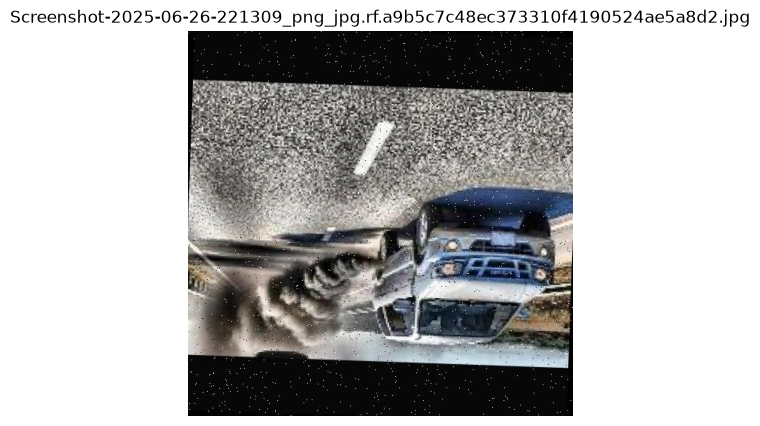


Image: 000054_jpg.rf.01c72e46c321946a32bbb61b81f0b28f.jpg
Size: (512, 512)
Label:
3 0.68290813671875 0.1842508828125 0.58315733203125 0.1370016015625 0.503050138671875 0.1627441640625 0.482311298828125 0.22416619921875 0.500255234375 0.301911314453125 0.43061544140625 0.4159175 0.433293416015625 0.478715361328125 0.38673131640625 0.592737224609375 0.44305296484375 0.616197033203125 0.5068818359375 0.57720432421875 0.52449691796875 0.630508349609375 0.47696233203125 0.671208033203125 0.486428046875 0.732313521484375 0.531182330078125 0.807698962890625 0.590968748046875 0.70624859765625 0.633536529296875 0.460521921875 0.64710173828125 0.480218119140625 0.63815245703125 0.693


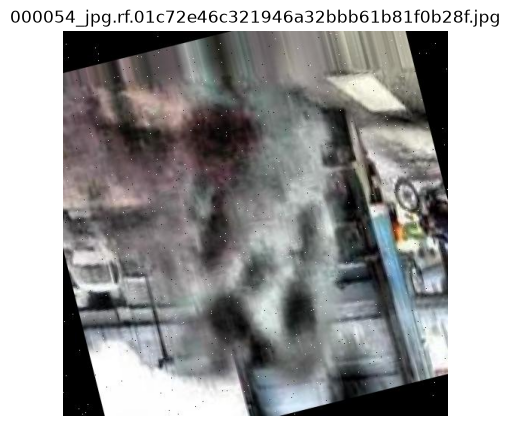


Image: 000015_jpg.rf.8be7ff287006089b646501e870b9d2c9.jpg
Size: (512, 512)
Label:
1 0.6572265625 0.58203125 0.529296875 0.7431640625


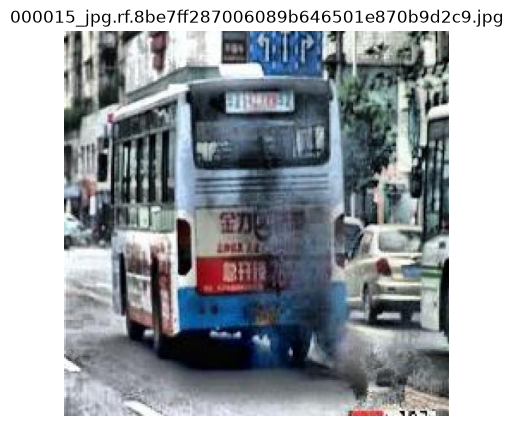


Image: 000129_jpg.rf.5023a77bea5fbe71e93d7990d331aa6d.jpg
Size: (512, 512)
Label:
1 0.380859375 0.404296875 0.76171875 0.48828125


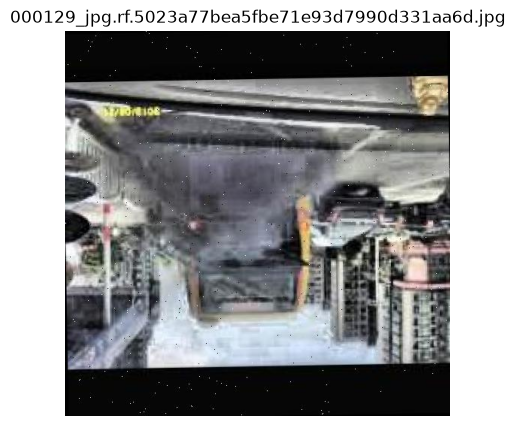

In [16]:
from PIL import Image
import matplotlib.pyplot as plt
import random

random.seed(42)

sample_images = list(
    (SMOKE_SOURCE / "train" / "images").glob("*")
)

sample_images = [
    p for p in sample_images
    if p.suffix.lower() in IMAGE_EXTS
]

for image_path in random.sample(
    sample_images, k=min(4, len(sample_images))
):
    label_path = (
        SMOKE_SOURCE / "train" / "labels" /
        f"{image_path.stem}.txt"
    )

    image = Image.open(image_path).convert("RGB")

    print("\nImage:", image_path.name)
    print("Size:", image.size)

    if label_path.exists():
        print("Label:")
        print(label_path.read_text(encoding="utf-8")[:600])
    else:
        print("No label file found.")

    plt.figure(figsize=(8, 5))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

### Cell 8 — Convert smoke annotations to YOLO bounding boxes

In [17]:
from pathlib import Path
from PIL import Image
from collections import Counter
import shutil

SOURCE = PROJECT / "-Smoke-Vehicles-Detection--2"
OUTPUT = PROJECT / "EcoWatch-Smoke-Converted"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SMOKE_CLASSES = {1, 2, 3}
SUSPICIOUS_CLASSES = {0}

if not SOURCE.exists():
    raise FileNotFoundError(SOURCE)

if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Inspect it or choose a new output path."
    )

def convert_annotation_line(line):
    """
    Convert one YOLO bbox or polygon line into a YOLO bbox.
    Return (class_id, x_center, y_center, width, height).
    """
    parts = line.split()

    if len(parts) < 5:
        raise ValueError(f"Too few values: {line}")

    class_id = int(parts[0])
    coords = [float(v) for v in parts[1:]]

    if not all(0 <= v <= 1 for v in coords):
        raise ValueError(f"Coordinates outside [0, 1]: {line}")

    # Standard YOLO bounding box: class + 4 coordinates.
    if len(coords) == 4:
        x_center, y_center, width, height = coords

    # Polygon: class + 3 or more (x, y) points.
    elif len(coords) >= 6 and len(coords) % 2 == 0:
        xs = coords[0::2]
        ys = coords[1::2]

        x_min, x_max = min(xs), max(xs)
        y_min, y_max = min(ys), max(ys)

        x_center = (x_min + x_max) / 2
        y_center = (y_min + y_max) / 2
        width = x_max - x_min
        height = y_max - y_min

    else:
        raise ValueError(f"Unrecognized annotation format: {line}")

    if width <= 0 or height <= 0:
        raise ValueError(f"Invalid bounding-box dimensions: {line}")

    # Merge the three smoke classes into class ID 0.
    return (0, x_center, y_center, width, height)


stats = Counter()
errors = []

for split in ["train", "valid", "test"]:
    src_images = SOURCE / split / "images"
    src_labels = SOURCE / split / "labels"

    dst_images = OUTPUT / split / "images"
    dst_labels = OUTPUT / split / "labels"

    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    if not src_images.exists() or not src_labels.exists():
        raise FileNotFoundError(
            f"Expected images and labels folders for split: {split}"
        )

    for image_path in sorted(src_images.iterdir()):
        if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTS:
            continue

        label_path = src_labels / f"{image_path.stem}.txt"

        if not label_path.exists():
            stats["missing_label"] += 1
            continue

        lines = [
            line.strip()
            for line in label_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]

        if not lines:
            stats["empty_label_skipped"] += 1
            continue

        try:
            parsed = []
            class_ids = []

            for line in lines:
                parts = line.split()
                original_class = int(parts[0])
                class_ids.append(original_class)

                if original_class in SMOKE_CLASSES:
                    parsed.append(convert_annotation_line(line))

                elif original_class in SUSPICIOUS_CLASSES:
                    # This image will be excluded below.
                    continue

                else:
                    raise ValueError(
                        f"Unexpected original class ID: {original_class}"
                    )

            # Exclude the entire image if it contains suspicious class 0.
            if any(c in SUSPICIOUS_CLASSES for c in class_ids):
                stats["suspicious_images_skipped"] += 1
                continue

            if not parsed:
                stats["no_smoke_boxes_skipped"] += 1
                continue

            # Copy the image and write converted annotations.
            shutil.copy2(image_path, dst_images / image_path.name)

            output_label = dst_labels / f"{image_path.stem}.txt"
            output_label.write_text(
                "".join(
                    f"{cls} {x:.8f} {y:.8f} {w:.8f} {h:.8f}\n"
                    for cls, x, y, w, h in parsed
                ),
                encoding="utf-8",
            )

            stats[f"{split}_images_kept"] += 1
            stats["smoke_boxes_written"] += len(parsed)

        except Exception as exc:
            errors.append((str(label_path), str(exc)))
            stats["conversion_errors"] += 1

print("Output:", OUTPUT)
print("\nSummary:")
for key, value in stats.items():
    print(f"{key}: {value}")

print("\nConversion errors:", len(errors))
for filename, error in errors[:10]:
    print(filename, "->", error)

Output: c:\Projects\smoke_vehicle_detection\EcoWatch-Smoke-Converted

Summary:
train_images_kept: 2655
smoke_boxes_written: 3150
suspicious_images_skipped: 6
empty_label_skipped: 3
valid_images_kept: 123
test_images_kept: 61

Conversion errors: 0


### Cell 9 — Verify the converted annotations

In [18]:
for split in ["train", "valid", "test"]:
    image_dir = OUTPUT / split / "images"
    label_dir = OUTPUT / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]

    problems = []
    total_boxes = 0

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            problems.append(f"Missing label: {image_path.name}")
            continue

        lines = [
            line.strip()
            for line in label_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]

        for line in lines:
            parts = line.split()

            if len(parts) != 5 or parts[0] != "0":
                problems.append(f"Invalid label: {label_path.name}: {line}")
                continue

            try:
                x, y, w, h = map(float, parts[1:])

                if not (
                    0 <= x <= 1 and 0 <= y <= 1
                    and 0 < w <= 1 and 0 < h <= 1
                    and x - w / 2 >= -1e-7
                    and y - h / 2 >= -1e-7
                    and x + w / 2 <= 1 + 1e-7
                    and y + h / 2 <= 1 + 1e-7
                ):
                    problems.append(f"Invalid box bounds: {label_path.name}")
                else:
                    total_boxes += 1

            except ValueError:
                problems.append(f"Non-numeric values: {label_path.name}")

    print(f"\n{split}: {len(images)} images, {total_boxes} boxes")
    print("Problems:", len(problems))
    for problem in problems[:5]:
        print(" -", problem)


train: 2655 images, 2946 boxes
Problems: 0

valid: 123 images, 135 boxes
Problems: 0

test: 61 images, 69 boxes
Problems: 0


### Cell 10 — Check the vehicle dataset before adding negatives

In [19]:
from collections import Counter

VEHICLE_SOURCE = PROJECT / "Dataset" / "vehicle detection"

for split in ["train", "valid", "test"]:
    label_dir = VEHICLE_SOURCE / split / "labels"
    image_dir = VEHICLE_SOURCE / split / "images"

    print(f"\n{split}:")
    print("Images folder exists:", image_dir.exists())
    print("Labels folder exists:", label_dir.exists())

    if label_dir.exists():
        class_counts = Counter()
        annotation_lengths = Counter()
        empty_files = 0

        for label_path in label_dir.glob("*.txt"):
            lines = [
                line.strip()
                for line in label_path.read_text(encoding="utf-8").splitlines()
                if line.strip()
            ]

            if not lines:
                empty_files += 1

            for line in lines:
                parts = line.split()
                annotation_lengths[len(parts)] += 1

                if parts:
                    class_counts[parts[0]] += 1

        print("Class IDs:", dict(class_counts))
        print("Values per line:", dict(annotation_lengths))
        print("Empty label files:", empty_files)


train:
Images folder exists: True
Labels folder exists: True
Class IDs: {'4': 580, '3': 636, '0': 340, '1': 299, '2': 507}
Values per line: {5: 2362}
Empty label files: 0

valid:
Images folder exists: True
Labels folder exists: True
Class IDs: {'0': 166, '1': 369, '3': 107, '4': 96, '2': 43}
Values per line: {5: 781}
Empty label files: 0

test:
Images folder exists: True
Labels folder exists: True
Class IDs: {'1': 42, '0': 90, '4': 167, '2': 28, '3': 49}
Values per line: {5: 376}
Empty label files: 0


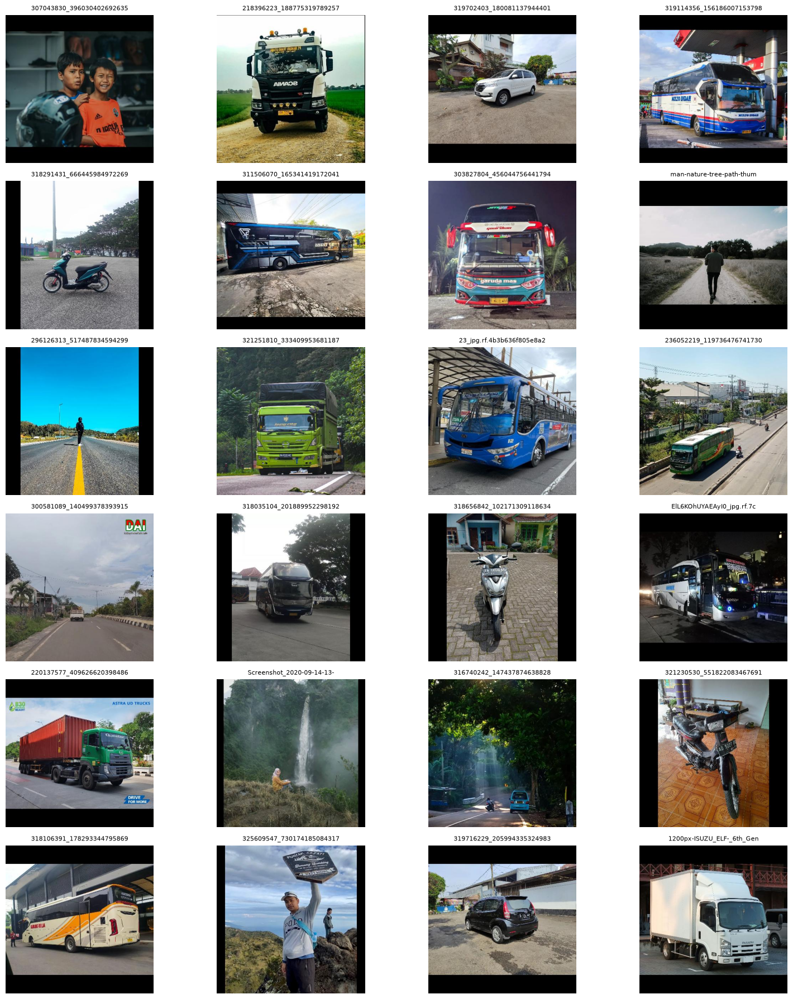

Images available: 1172
Images previewed: 24


In [20]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random
import math

VEHICLE_SOURCE = PROJECT / "Dataset" / "vehicle detection"
VEHICLE_TRAIN_IMAGES = VEHICLE_SOURCE / "train" / "images"

vehicle_images = sorted(
    p for p in VEHICLE_TRAIN_IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

random.seed(42)
sample = random.sample(vehicle_images, min(24, len(vehicle_images)))

cols = 4
rows = math.ceil(len(sample) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3))
axes = list(axes.flat)

for ax, image_path in zip(axes, sample):
    try:
        with Image.open(image_path) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(image_path.name[:25], fontsize=8)
        ax.axis("off")
    except Exception as e:
        ax.set_title(f"Could not open: {image_path.name[:15]}")
        ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Images available:", len(vehicle_images))
print("Images previewed:", len(sample))

### Cell - Create a reviewed-negative list

In [21]:
import pandas as pd

REVIEW_CSV = PROJECT / "vehicle_negative_review.csv"

review_df = pd.DataFrame({
    "image_path": [str(p) for p in vehicle_images],
    "review_status": ["pending"] * len(vehicle_images),
})

review_df.to_csv(REVIEW_CSV, index=False, encoding="utf-8")

print("Review list created:", REVIEW_CSV)
print(review_df.head(10).to_string(index=False))

Review list created: c:\Projects\smoke_vehicle_detection\vehicle_negative_review.csv
                                                                                                                                                            image_path review_status
                                           c:\Projects\smoke_vehicle_detection\Dataset\vehicle detection\train\images\-_57_jpg.rf.49808d5d7901748b58f2ef9ad43838ec.jpg       pending
                                    c:\Projects\smoke_vehicle_detection\Dataset\vehicle detection\train\images\-c7cae33d7d_jpg.rf.d046fe1a9527863d127cf963d0abe1b9.jpg       pending
           c:\Projects\smoke_vehicle_detection\Dataset\vehicle detection\train\images\0000147617-e4eb190337827f8bbbcc9317d_jpg.rf.4b2fe0cbf62d7b938f3939c0eb6f809a.jpg       pending
           c:\Projects\smoke_vehicle_detection\Dataset\vehicle detection\train\images\0000161190-eff4a7d6440628a6ed58e9d9a_jpg.rf.9132501343ff03ceeef02ea94acd60dc.jpg       pending
          

In [22]:
%pip install ipywidgets pandas pillow

Note: you may need to restart the kernel to use updated packages.


### Cell 12 - Create an image review tool

In [23]:
from pathlib import Path

VEHICLE_SOURCE = PROJECT / "Dataset" / "vehicle detection"

print("Configuration and documentation files:")

for p in VEHICLE_SOURCE.rglob("*"):
    if p.is_file() and p.suffix.lower() in {
        ".yaml", ".yml", ".names", ".txt", ".md"
    }:
        if p.parent.name != "labels":
            print(p.relative_to(VEHICLE_SOURCE))

print("\nSample annotations from training data:")

label_dir = VEHICLE_SOURCE / "train" / "labels"
shown = 0

for label_path in sorted(label_dir.glob("*.txt")):
    lines = label_path.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines()

    if lines:
        print(f"\n{label_path.name}")
        for line in lines[:3]:
            print(" ", line)
        shown += 1

    if shown >= 5:
        break

Configuration and documentation files:

Sample annotations from training data:

-_57_jpg.rf.49808d5d7901748b58f2ef9ad43838ec.txt
  4 0.43990384615384615 0.40865384615384615 0.8725961538461539 0.5552884615384616

-c7cae33d7d_jpg.rf.d046fe1a9527863d127cf963d0abe1b9.txt
  4 0.49038461538461536 0.5504807692307693 0.9567307692307693 0.5432692307692307
  4 0.9615384615384616 0.46153846153846156 0.07692307692307693 0.23557692307692307

0000147617-e4eb190337827f8bbbcc9317d_jpg.rf.4b2fe0cbf62d7b938f3939c0eb6f809a.txt
  4 0.5192307692307693 0.5216346153846154 0.8004807692307693 0.6057692307692307

0000161190-eff4a7d6440628a6ed58e9d9a_jpg.rf.9132501343ff03ceeef02ea94acd60dc.txt
  4 0.49278846153846156 0.5024038461538461 0.9014423076923077 0.5889423076923077
  4 0.04807692307692308 0.4014423076923077 0.09375 0.2860576923076923
  4 0.7908653846153846 0.3485576923076923 0.4182692307692308 0.32211538461538464

013877-1-lg_jpg.rf.0075e439bd59adb27ba5fca3fc94f2a0.txt
  3 0.15625 0.6490384615384616 0.04

### identify the vehicle classes

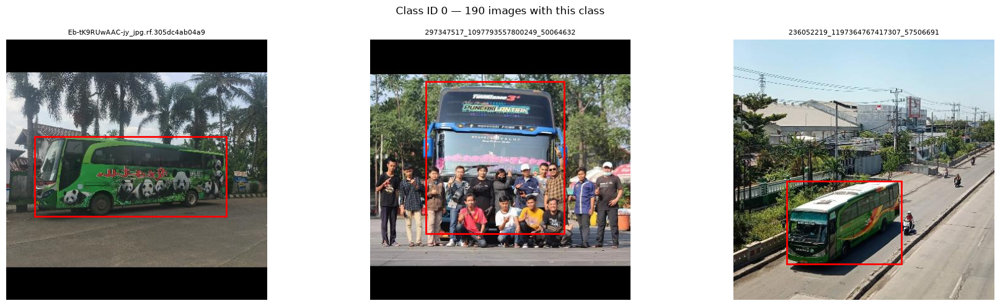

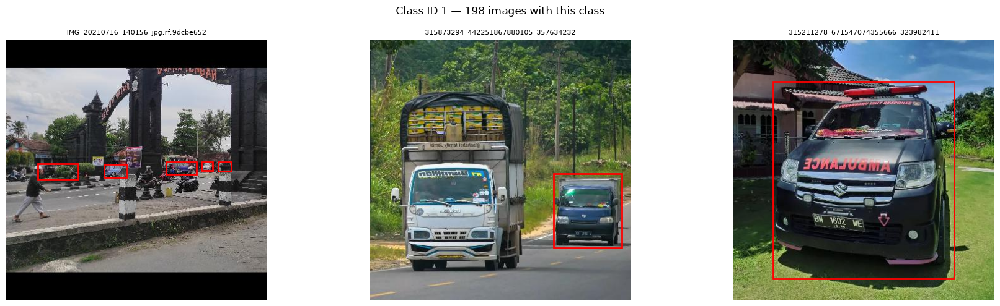

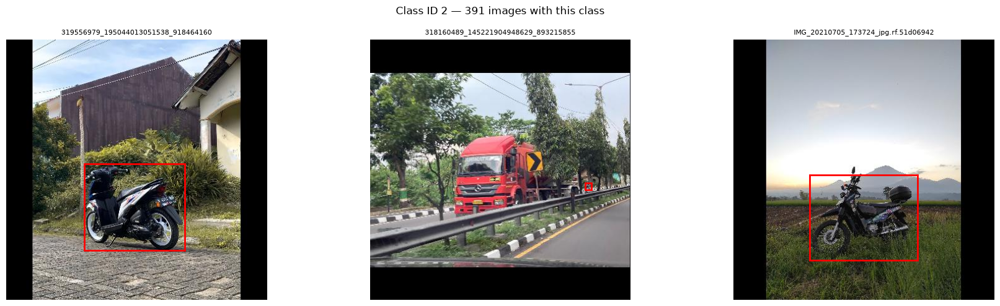

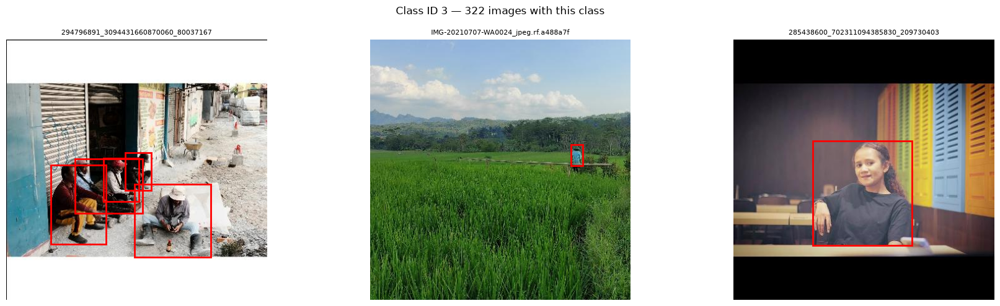

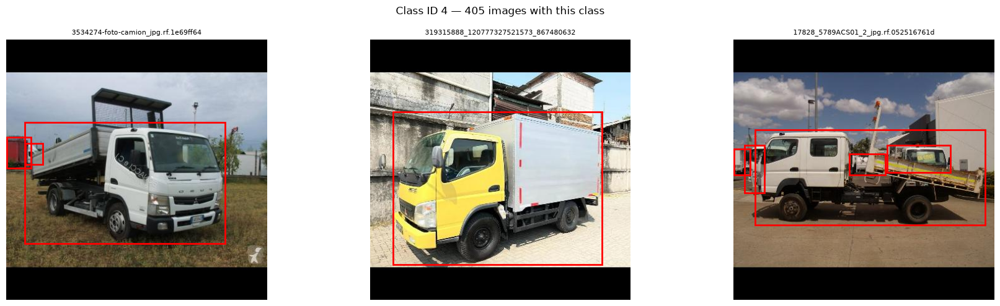

In [24]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import defaultdict
import random

VEHICLE_SOURCE = PROJECT / "Dataset" / "vehicle detection"
IMG_DIR = VEHICLE_SOURCE / "train" / "images"
LBL_DIR = VEHICLE_SOURCE / "train" / "labels"

# Collect images by annotation class ID
class_samples = defaultdict(list)

for label_path in LBL_DIR.glob("*.txt"):
    image_path = IMG_DIR / f"{label_path.stem}.jpg"

    if not image_path.exists():
        matches = [
            p for p in IMG_DIR.glob(f"{label_path.stem}.*")
            if p.suffix.lower() in IMAGE_EXTS
        ]
        if not matches:
            continue
        image_path = matches[0]

    for line in label_path.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines():
        parts = line.split()
        if len(parts) == 5:
            class_id = parts[0]
            if image_path not in class_samples[class_id]:
                class_samples[class_id].append(image_path)

random.seed(42)

for class_id in sorted(class_samples, key=lambda x: int(x)):
    samples = random.sample(
        class_samples[class_id],
        min(3, len(class_samples[class_id]))
    )

    fig, axes = plt.subplots(
        1, len(samples), figsize=(6 * len(samples), 5)
    )
    if len(samples) == 1:
        axes = [axes]

    for ax, image_path in zip(axes, samples):
        with Image.open(image_path) as im:
            im = im.convert("RGB")
            ax.imshow(im)
            width, height = im.size

        label_path = LBL_DIR / f"{image_path.stem}.txt"

        for line in label_path.read_text(
            encoding="utf-8", errors="replace"
        ).splitlines():
            parts = line.split()
            if len(parts) != 5 or parts[0] != class_id:
                continue

            _, xc, yc, bw, bh = parts
            xc, yc, bw, bh = map(float, (xc, yc, bw, bh))

            x = (xc - bw / 2) * width
            y = (yc - bh / 2) * height

            ax.add_patch(
                patches.Rectangle(
                    (x, y),
                    bw * width,
                    bh * height,
                    fill=False,
                    edgecolor="red",
                    linewidth=2,
                )
            )

        ax.set_title(image_path.name[:35], fontsize=8)
        ax.axis("off")

    fig.suptitle(
        f"Class ID {class_id} — {len(class_samples[class_id])} images with this class"
    )
    plt.tight_layout()
    plt.show()

### automatically collect candidate vehicle images

In [25]:
from pathlib import Path
from PIL import Image
import shutil
import random

VEHICLE_SOURCE = PROJECT / "Dataset" / "vehicle detection"
CANDIDATE_OUTPUT = PROJECT / "EcoWatch-Negative-Candidates"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SELECTED_CLASSES = {"0", "4"}  # Candidate bus and truck classes

if CANDIDATE_OUTPUT.exists():
    raise FileExistsError(
        f"{CANDIDATE_OUTPUT} already exists. "
        "Choose another output folder or inspect the existing one."
    )

total_copied = 0
seen_images = set()

for split in ["train", "valid", "test"]:
    image_dir = VEHICLE_SOURCE / split / "images"
    label_dir = VEHICLE_SOURCE / split / "labels"

    out_images = CANDIDATE_OUTPUT / split / "images"
    out_labels = CANDIDATE_OUTPUT / split / "labels"

    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    for label_path in label_dir.glob("*.txt"):
        lines = [
            line.strip()
            for line in label_path.read_text(
                encoding="utf-8", errors="replace"
            ).splitlines()
            if line.strip()
        ]

        # Select images whose annotations include class 0 or class 4.
        classes_present = {
            line.split()[0] for line in lines if line.split()
        }

        if not classes_present.intersection(SELECTED_CLASSES):
            continue

        matches = [
            p for p in image_dir.glob(f"{label_path.stem}.*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        ]

        if not matches:
            continue

        image_path = matches[0]

        # Avoid copying the same image twice.
        unique_key = str(image_path.resolve()).lower()
        if unique_key in seen_images:
            continue
        seen_images.add(unique_key)

        # Confirm the image can be opened.
        try:
            with Image.open(image_path) as im:
                im.verify()
        except Exception:
            continue

        shutil.copy2(image_path, out_images / image_path.name)

        # Negative detection example: empty YOLO label file.
        (out_labels / f"{image_path.stem}.txt").write_text(
            "", encoding="utf-8"
        )

        total_copied += 1

print("Candidate output:", CANDIDATE_OUTPUT)
print("Candidate images copied:", total_copied)
print("All copied label files are empty.")
print("Review for visible smoke before training.")

Candidate output: c:\Projects\smoke_vehicle_detection\EcoWatch-Negative-Candidates
Candidate images copied: 903
All copied label files are empty.
Review for visible smoke before training.


Total candidate images: 903
Review sheets: 19
Review CSV: C:\Projects\smoke_vehicle_detection\EcoWatch-Negative-Review\negative_image_review.csv
Review folder: C:\Projects\smoke_vehicle_detection\EcoWatch-Negative-Review


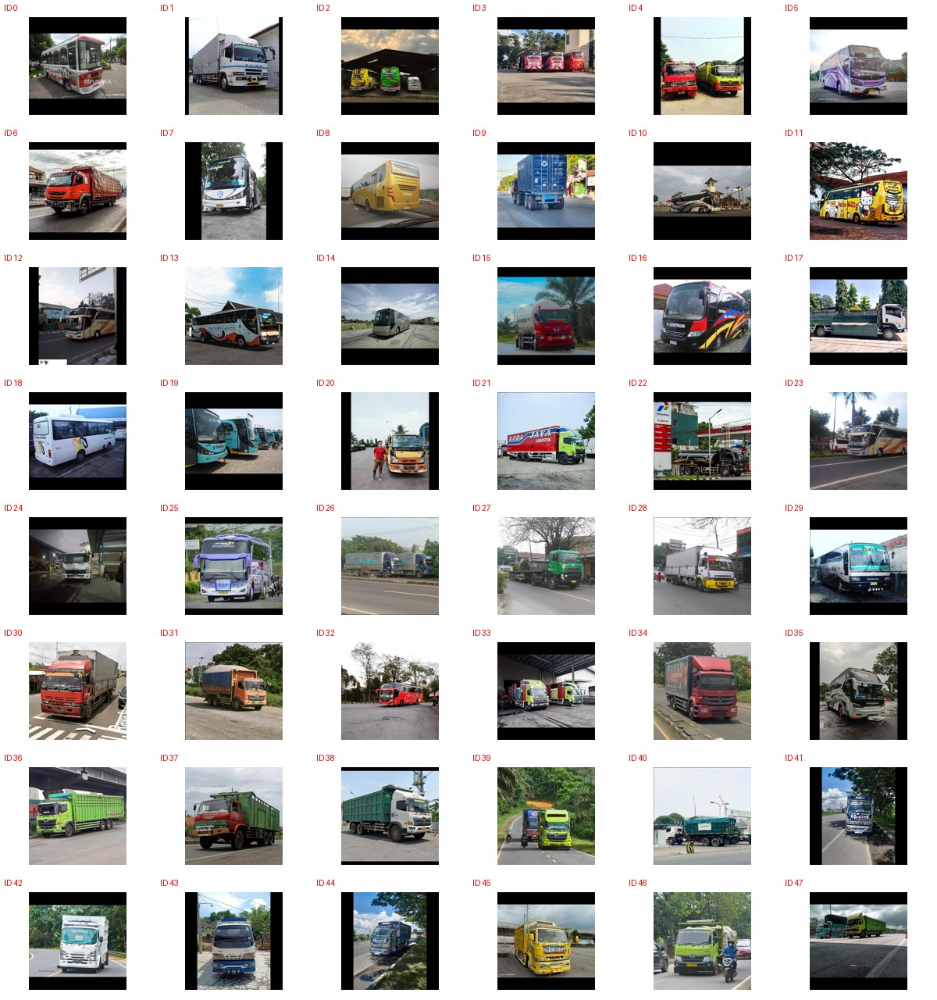

In [26]:
from pathlib import Path
from PIL import Image, ImageDraw
import pandas as pd
import math

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")
CANDIDATES = PROJECT / "EcoWatch-Negative-Candidates"
REVIEW_DIR = PROJECT / "EcoWatch-Negative-Review"

REVIEW_DIR.mkdir(parents=True, exist_ok=True)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = sorted(
    p for p in CANDIDATES.rglob("*")
    if p.is_file()
    and p.suffix.lower() in extensions
    and p.parent.name == "images"
)

# Create a stable ID for each candidate image.
df = pd.DataFrame({
    "review_id": range(len(images)),
    "split": [p.parent.parent.name for p in images],
    "image_path": [str(p) for p in images],
    "review_status": ["pending"] * len(images),
})

csv_path = REVIEW_DIR / "negative_image_review.csv"
df.to_csv(csv_path, index=False)

# Generate sheets: 48 images per sheet, 6 columns x 8 rows.
per_sheet = 48
cols, rows = 6, 8
cell_w, cell_h = 200, 160
thumb_w, thumb_h = 190, 125

for start in range(0, len(df), per_sheet):
    batch = df.iloc[start:start + per_sheet]
    sheet = Image.new(
        "RGB",
        (cols * cell_w, rows * cell_h),
        "white"
    )
    draw = ImageDraw.Draw(sheet)

    for position, (_, item) in enumerate(batch.iterrows()):
        local_row = position // cols
        local_col = position % cols
        x = local_col * cell_w
        y = local_row * cell_h

        image_path = Path(item["image_path"])

        try:
            with Image.open(image_path) as source:
                thumb = source.convert("RGB")
                thumb.thumbnail((thumb_w, thumb_h))

            px = x + (cell_w - thumb.width) // 2
            py = y + 22 + (thumb_h - thumb.height) // 2
            sheet.paste(thumb, (px, py))

            draw.text(
                (x + 5, y + 4),
                f"ID {item['review_id']}",
                fill="red"
            )
        except Exception:
            draw.text((x + 5, y + 5), "Could not load", fill="red")

    sheet_number = start // per_sheet + 1
    sheet_path = REVIEW_DIR / f"review_sheet_{sheet_number:02d}.jpg"
    sheet.save(sheet_path, quality=90)

print("Total candidate images:", len(df))
print("Review sheets:", math.ceil(len(df) / per_sheet))
print("Review CSV:", csv_path)
print("Review folder:", REVIEW_DIR)

# Display the first sheet in the notebook.
display(Image.open(REVIEW_DIR / "review_sheet_01.jpg"))

### Build the final combined dataset

In [27]:
from pathlib import Path
import shutil
import yaml

PROJECT = Path(r"C:\Projects\smoke_vehicle_detection")

SMOKE_SOURCE = PROJECT / "EcoWatch-Smoke-Converted"
NEGATIVE_SOURCE = PROJECT / "EcoWatch-Negative-Candidates"
OUTPUT = PROJECT / "EcoWatch-Final-YOLO"

# Safety checks
for path in [SMOKE_SOURCE, NEGATIVE_SOURCE]:
    if not path.exists():
        raise FileNotFoundError(f"Dataset folder not found: {path}")

if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Inspect it before choosing another output."
    )

# Verify that both datasets have all three splits.
splits = ["train", "valid", "test"]

for split in splits:
    for source in [SMOKE_SOURCE, NEGATIVE_SOURCE]:
        for subfolder in ["images", "labels"]:
            folder = source / split / subfolder
            if not folder.exists():
                raise FileNotFoundError(f"Missing folder: {folder}")

# Create output directories
for split in splits:
    (OUTPUT / split / "images").mkdir(parents=True)
    (OUTPUT / split / "labels").mkdir(parents=True)

smoke_images_copied = 0
smoke_boxes_written = 0
negative_images_copied = 0

# Copy smoke images and remap every smoke class to class 0.
for split in splits:
    src_images = SMOKE_SOURCE / split / "images"
    src_labels = SMOKE_SOURCE / split / "labels"
    dst_images = OUTPUT / split / "images"
    dst_labels = OUTPUT / split / "labels"

    for image_path in src_images.iterdir():
        if not image_path.is_file():
            continue

        label_path = src_labels / f"{image_path.stem}.txt"

        if not label_path.exists():
            raise FileNotFoundError(
                f"Missing smoke annotation: {label_path}"
            )

        new_lines = []

        for line in label_path.read_text(
            encoding="utf-8"
        ).splitlines():
            if not line.strip():
                continue

            parts = line.split()

            if len(parts) != 5:
                raise ValueError(
                    f"Unexpected annotation format in {label_path}: {line}"
                )

            # Convert all smoke types into the single class: smoke (ID 0).
            new_lines.append("0 " + " ".join(parts[1:]))

        if not new_lines:
            raise ValueError(
                f"Smoke image has no bounding boxes: {image_path}"
            )

        # Prefix filenames to prevent collisions.
        new_name = "smoke_" + image_path.name
        shutil.copy2(image_path, dst_images / new_name)

        (dst_labels / f"{Path(new_name).stem}.txt").write_text(
            "\n".join(new_lines) + "\n",
            encoding="utf-8"
        )

        smoke_images_copied += 1
        smoke_boxes_written += len(new_lines)

# Copy reviewed negative images with EMPTY annotation files.
for split in splits:
    src_images = NEGATIVE_SOURCE / split / "images"
    src_labels = NEGATIVE_SOURCE / split / "labels"
    dst_images = OUTPUT / split / "images"
    dst_labels = OUTPUT / split / "labels"

    for image_path in src_images.iterdir():
        if not image_path.is_file():
            continue

        label_path = src_labels / f"{image_path.stem}.txt"

        if not label_path.exists():
            raise FileNotFoundError(
                f"Missing negative annotation: {label_path}"
            )

        if label_path.read_text(encoding="utf-8").strip():
            raise ValueError(
                f"Negative label is not empty: {label_path}"
            )

        new_name = "negative_" + image_path.name
        shutil.copy2(image_path, dst_images / new_name)

        # Empty file means no smoke objects are annotated.
        (dst_labels / f"{Path(new_name).stem}.txt").write_text(
            "", encoding="utf-8"
        )

        negative_images_copied += 1

# Create the YOLO dataset configuration.
data_yaml = {
    "path": str(OUTPUT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {0: "smoke"},
    "nc": 1,
}

with (OUTPUT / "data.yaml").open("w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print("DATASET CREATED")
print("Location:", OUTPUT)
print("Smoke images:", smoke_images_copied)
print("Smoke boxes:", smoke_boxes_written)
print("Negative images:", negative_images_copied)
print("Total images:", smoke_images_copied + negative_images_copied)
print("Class configuration: 0 = smoke")
print("YAML:", OUTPUT / "data.yaml")

DATASET CREATED
Location: C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO
Smoke images: 2839
Smoke boxes: 3150
Negative images: 903
Total images: 3742
Class configuration: 0 = smoke
YAML: C:\Projects\smoke_vehicle_detection\EcoWatch-Final-YOLO\data.yaml


### Verify the final dataset

In [28]:
from collections import Counter

for split in ["train", "valid", "test"]:
    image_dir = OUTPUT / split / "images"
    label_dir = OUTPUT / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    empty_labels = 0
    class_ids = Counter()
    problems = []

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            problems.append(f"Missing label: {image_path.name}")
            continue

        lines = [
            line.strip()
            for line in label_path.read_text(
                encoding="utf-8"
            ).splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1
            continue

        for line in lines:
            parts = line.split()

            if len(parts) != 5 or parts[0] != "0":
                problems.append(
                    f"Invalid label: {label_path.name}: {line}"
                )
                continue

            try:
                values = [float(v) for v in parts[1:]]
                if not all(0 <= v <= 1 for v in values):
                    problems.append(
                        f"Coordinates outside 0-1: {label_path.name}"
                    )
                if values[2] <= 0 or values[3] <= 0:
                    problems.append(
                        f"Invalid box size: {label_path.name}"
                    )
            except ValueError:
                problems.append(f"Non-numeric values: {label_path.name}")

            class_ids[parts[0]] += 1

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Empty labels (negative examples):", empty_labels)
    print("Smoke boxes:", class_ids.get("0", 0))
    print("Problems:", len(problems))

    for problem in problems[:5]:
        print(" -", problem)


TRAIN
Images: 3234
Empty labels (negative examples): 579
Smoke boxes: 2946
Problems: 0

VALID
Images: 283
Empty labels (negative examples): 160
Smoke boxes: 135
Problems: 0

TEST
Images: 225
Empty labels (negative examples): 164
Smoke boxes: 69
Problems: 0
